<a href="https://colab.research.google.com/github/cmburban/MAT-422/blob/main/MAT422_Section_4_1_4_2_Graph_Modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT 422 - Sections 4.1 and 4.2: Graphs and Graph Modeling

**Topics:** Graph basics and adjacency representations, Degree and neighbors, Graph traversal, Graph and graph modeling

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

np.set_printoptions(precision=3, suppress=True)

## 4.1.1 Graph Basics and Adjacency Representations

A graph is a mathematical structure used to represent relationships or connections between objects. It consists of vertices (also called nodes) and edges that connect pairs of vertices.

Graphs can be represented in different ways. One common method is an **adjacency matrix**, which uses a two-dimensional array to show which vertices are connected.

For an unweighted graph:

- A value of 1 indicates that two vertices are connected.
- A value of 0 indicates that two vertices are not connected.
- For an undirected graph, the adjacency matrix is symmetric because connections work in both directions.

In this example, I will create a small undirected graph containing five vertices (A, B, C, D, and E). I will represent its connections using an adjacency matrix and examine the resulting values.

In [3]:
nodes = ["A", "B", "C", "D", "E"]
edges = [("A","B"), ("A","C"), ("B","D"), ("C","D"), ("D","E")]
index = {node: i for i, node in enumerate(nodes)}
adj = np.zeros((len(nodes), len(nodes)), dtype=int)

for u, v in edges:
    adj[index[u], index[v]] = 1
    adj[index[v], index[u]] = 1

print("Adjacency matrix:")
print(adj)
print("Degrees:", dict(zip(nodes, adj.sum(axis=1))))

Adjacency matrix:
[[0 1 1 0 0]
 [1 0 0 1 0]
 [1 0 0 1 0]
 [0 1 1 0 1]
 [0 0 0 1 0]]
Degrees: {'A': np.int64(2), 'B': np.int64(2), 'C': np.int64(2), 'D': np.int64(3), 'E': np.int64(1)}


In [4]:
# Verify the adjacency matrix
print("Matrix dimensions:", adj.shape)

# Check whether the matrix is symmetric
print("Is the adjacency matrix symmetric:",
      np.array_equal(adj, adj.T))

# Count the total number of edges
edge_count = np.sum(adj) // 2

print("Number of vertices:", len(nodes))
print("Number of edges:", edge_count)

# Verify that the matrix contains only 0s and 1s
print("Contains only 0s and 1s:",
      np.all(np.isin(adj, [0, 1])))

Matrix dimensions: (5, 5)
Is the adjacency matrix symmetric: True
Number of vertices: 5
Number of edges: 5
Contains only 0s and 1s: True


### Interpretation

The adjacency matrix represents the connections between the five vertices in the graph. Each value of 1 indicates a connection between two vertices, while 0 indicates no connection. The matrix is symmetric because the graph is undirected, meaning every connection works in both directions. The verification confirms that the graph contains five vertices and five edges.

## 4.1.2 Degree and Neighbors

The degree of a vertex is the number of edges connected to that vertex. Neighbors are the vertices that are directly connected to a particular vertex.

An adjacency list is another way to represent a graph. Instead of using a matrix, it stores each vertex alongside a list of its neighboring vertices.

For an undirected graph, the degree of a vertex is equal to the number of neighbors it has.

In this example, I will create an adjacency list from the graph and examine the degree and neighbors of each vertex.

In [5]:
# Create an adjacency list
adj_list = {node: [] for node in nodes}

for u, v in edges:
    adj_list[u].append(v)
    adj_list[v].append(u)

# Display each vertex and its neighbors
print("Adjacency list:")
for node in nodes:
    print(node, ":", adj_list[node])

# Calculate the degree of each vertex
degrees = {node: len(adj_list[node]) for node in nodes}

print("\nDegree of each vertex:")
print(degrees)

# Display the neighbors of a selected vertex
selected_node = "A"

print("\nNeighbors of", selected_node, ":",
      adj_list[selected_node])

Adjacency list:
A : ['B', 'C']
B : ['A', 'D']
C : ['A', 'D']
D : ['B', 'C', 'E']
E : ['D']

Degree of each vertex:
{'A': 2, 'B': 2, 'C': 2, 'D': 3, 'E': 1}

Neighbors of A : ['B', 'C']


In [6]:
# Verify that each vertex's degree equals its number of neighbors
for node in nodes:
    print(
        f"{node}: Degree = {degrees[node]}, "
        f"Number of neighbors = {len(adj_list[node])}"
    )

# Check that the total degree equals twice the number of edges
total_degree = sum(degrees.values())
number_of_edges = len(edges)

print("\nTotal degree:", total_degree)
print("Twice the number of edges:", 2 * number_of_edges)

print("Degree sum verification:",
      total_degree == 2 * number_of_edges)

A: Degree = 2, Number of neighbors = 2
B: Degree = 2, Number of neighbors = 2
C: Degree = 2, Number of neighbors = 2
D: Degree = 3, Number of neighbors = 3
E: Degree = 1, Number of neighbors = 1

Total degree: 10
Twice the number of edges: 10
Degree sum verification: True


### Interpretation

The adjacency list shows which vertices are directly connected to one another. Each vertex's degree matches the number of neighbors it has. The total degree of the graph is twice the number of edges because every undirected edge connects two vertices. The verification confirms this relationship.

## 4.1.3 Graph Traversal

Graph traversal is the process of visiting vertices in a graph to explore its structure and connections. Two common graph traversal algorithms are Breadth-First Search (BFS) and Depth-First Search (DFS).

**Breadth-First Search (BFS)** explores a graph level by level. It visits all neighboring vertices before moving to vertices farther away. BFS typically uses a queue to keep track of which vertices should be visited next.

**Depth-First Search (DFS)** explores one path as far as possible before returning to explore other paths. DFS typically uses a stack or recursion to keep track of vertices.

Both algorithms use a starting vertex and keep track of visited vertices to avoid processing the same vertex multiple times.

In this example, I will implement BFS and DFS using the adjacency list from the previous section and compare their traversal orders.

In [7]:
# Breadth-First Search (BFS)
def bfs(graph, start):
    visited = []
    queue = [start]

    while queue:
        node = queue.pop(0)

        if node not in visited:
            visited.append(node)

            for neighbor in graph[node]:
                if neighbor not in visited and neighbor not in queue:
                    queue.append(neighbor)

    return visited


# Depth-First Search (DFS)
def dfs(graph, start):
    visited = []
    stack = [start]

    while stack:
        node = stack.pop()

        if node not in visited:
            visited.append(node)

            for neighbor in reversed(graph[node]):
                if neighbor not in visited:
                    stack.append(neighbor)

    return visited


# Run both algorithms starting at vertex A
bfs_order = bfs(adj_list, "A")
dfs_order = dfs(adj_list, "A")

print("BFS traversal:", bfs_order)
print("DFS traversal:", dfs_order)

BFS traversal: ['A', 'B', 'C', 'D', 'E']
DFS traversal: ['A', 'B', 'D', 'C', 'E']


In [8]:
# Verify that both algorithms visit every vertex
print("Number of vertices:", len(nodes))
print("BFS visited:", len(bfs_order))
print("DFS visited:", len(dfs_order))

print("\nBFS visits every vertex:",
      set(bfs_order) == set(nodes))

print("DFS visits every vertex:",
      set(dfs_order) == set(nodes))

# Verify that no vertex is visited more than once
print("BFS has no repeated vertices:",
      len(bfs_order) == len(set(bfs_order)))

print("DFS has no repeated vertices:",
      len(dfs_order) == len(set(dfs_order)))

Number of vertices: 5
BFS visited: 5
DFS visited: 5

BFS visits every vertex: True
DFS visits every vertex: True
BFS has no repeated vertices: True
DFS has no repeated vertices: True


### Interpretation

BFS and DFS explore the same graph but visit vertices in different orders. BFS explores neighboring vertices before moving farther away, while DFS follows a path before backtracking. The verification confirms that both algorithms visit all five vertices without repeating any vertices. This demonstrates how different traversal strategies can be used to explore a graph.

## 4.2.1 Graph and Graph Modeling

Graph modeling is the process of representing real-world objects and their relationships using vertices and edges.

A graph can represent many different types of systems, including social networks, transportation routes, and computer networks.

For example, a small social network can be represented as an undirected graph:

- Each person represents a vertex.
- A friendship between two people represents an edge.
- Each edge represents a connection between two people.

Graphs can also be weighted, meaning that each edge has a numerical value representing something such as distance, cost, or time.

In this example, I will model a small transportation network. Each location will represent a vertex, and each road will represent a weighted edge. I will use the weights to represent the distances between locations.

In [9]:
# Model a small transportation network
locations = ["Home", "School", "Store", "Park", "Library"]

# Each edge represents a road and its distance
roads = [
    ("Home", "School", 5),
    ("Home", "Store", 3),
    ("School", "Park", 4),
    ("Store", "Park", 6),
    ("Park", "Library", 2),
    ("School", "Library", 7)
]

# Create a weighted adjacency list
transportation_graph = {location: [] for location in locations}

for start, end, distance in roads:
    transportation_graph[start].append((end, distance))
    transportation_graph[end].append((start, distance))

# Display the transportation network
print("Transportation Network:")
for location in locations:
    print(location, ":", transportation_graph[location])

Transportation Network:
Home : [('School', 5), ('Store', 3)]
School : [('Home', 5), ('Park', 4), ('Library', 7)]
Store : [('Home', 3), ('Park', 6)]
Park : [('School', 4), ('Store', 6), ('Library', 2)]
Library : [('Park', 2), ('School', 7)]


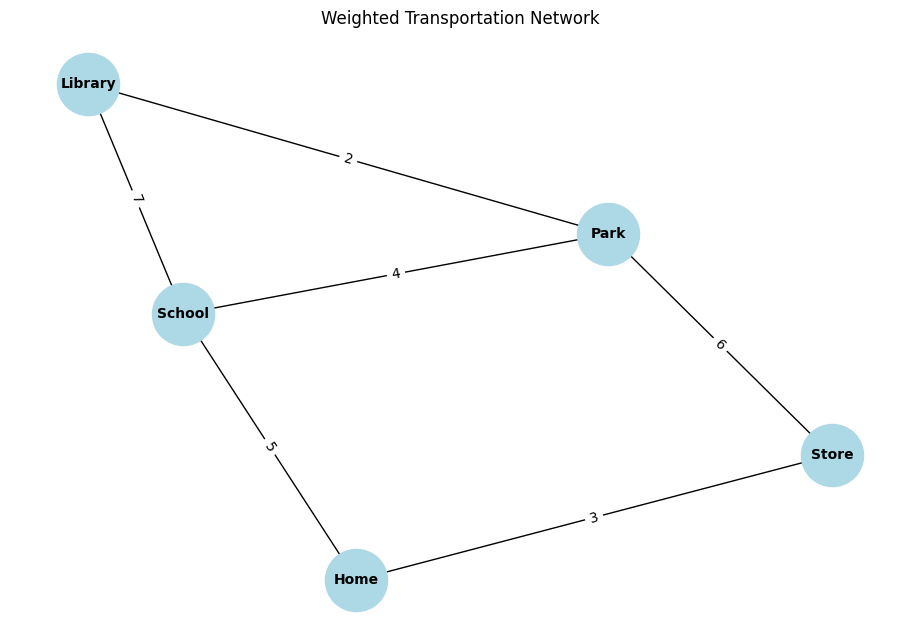

In [10]:
import networkx as nx

# Create a weighted graph
G = nx.Graph()

for start, end, distance in roads:
    G.add_edge(start, end, weight=distance)

# Draw the graph
plt.figure(figsize=(9, 6))

pos = nx.spring_layout(G, seed=422)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=2000,
    node_color="lightblue",
    font_size=10,
    font_weight="bold"
)

# Display the distance on each edge
edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

plt.title("Weighted Transportation Network")
plt.show()

In [11]:
# Verify the transportation network
print("Number of locations:", G.number_of_nodes())
print("Number of roads:", G.number_of_edges())

# Calculate the total distance of all roads
total_distance = sum(
    distance for start, end, distance in roads
)

print("Total distance of all roads:", total_distance)

# Find the roads connected to a selected location
selected_location = "School"

print("\nRoads connected to", selected_location, ":",
      transportation_graph[selected_location])

print("\nEvery location is represented:",
      set(G.nodes()) == set(locations))

print("Every road is represented:",
      G.number_of_edges() == len(roads))

Number of locations: 5
Number of roads: 6
Total distance of all roads: 27

Roads connected to School : [('Home', 5), ('Park', 4), ('Library', 7)]

Every location is represented: True
Every road is represented: True


### Interpretation

The transportation network demonstrates how graphs can represent real-world systems. Each location is represented by a vertex, while the roads connecting them are represented by weighted edges. The edge weights represent the distances between locations. The visualization makes it easier to understand the connections, while the verification confirms that all five locations and six roads are represented in the graph.

## End of Notebook Reflection

In these sections, I learned how graphs represent objects and the relationships between them. I explored how vertices and edges form a graph and how adjacency matrices and adjacency lists can be used to represent connections.

I also learned how to calculate the degree of a vertex and identify its neighbors. Through Breadth-First Search (BFS) and Depth-First Search (DFS), I explored different ways to visit and navigate vertices in a graph.

Finally, I learned how graphs can represent real-world systems. By creating a weighted transportation network, I was able to see how locations and distances can be modeled using vertices and edges.

## References

[Mathematical Methods in Data Science - Elsevier (2023)](https://doi.org/10.1016/B978-0-44-318679-0.00007-7)

[Matplotlib](https://matplotlib.org/stable/)

[NetworkX](https://networkx.org/documentation/stable/)

[Numpy - Singular Value Decomposition](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html)

[OpenAI - ChatGPT (2026)](https://chatgpt.com)

## Submission Checklist

- I explained each concept in words before or after the code. [DONE]
- I verified important claims numerically or visually. [DONE]
- I changed or extended at least one example so the notebook reflects my own work. [DONE]
- I ran the notebook from top to bottom without errors. [DONE]
- I saved the notebook from Google Colab directly to GitHub, following the course instructions. [DONE]